# Neural PDE Exercises · 05
## Inverse diffusion and informative sensors

**Course section:** Hybrid PDE–data methods. **Time:** 35–50 minutes.
This notebook is self-contained: select **Restart Kernel and Run All Cells** in a
fresh Python 3.11+ kernel. CPU / float64; the supplied run is a working baseline.

[All practical exercises](README.md) · [Laboratory guide](../NOTEBOOK_README.md) ·
[Related laboratory](../Neural_PDE_03_inverse.ipynb)

**How to work:** predict the outcome, run the baseline, then edit the marked
settings and rerun all cells. Keep a small results table and answer the reflection
questions. Use the same seed and training budget when comparing methods.

**Notation:** $u$ is the reference state, $u_\theta$ the neural state,
$r_\theta=\mathcal L u_\theta-f$, $\widehat{\mathcal J}$ a sampled loss,
and $\mathcal E$ an energy. Reference values are used for checking errors after
training, except when observations are explicitly supplied.

## 1 · Predict before computing

Infer a positive diffusivity $\kappa$ from
$$-\kappa u''=\pi^2\sin(\pi x),\qquad u(0)=u(1)=0.$$
Use the deliberately small sine-feature model $u_\theta(x)=a\sin(\pi x)$.
The amplitude $a$ and $\log\kappa$ are trainable. This reduced model isolates
identifiability from the cost of fitting a general MLP.

The PDE determines only $\kappa a=1$. Without state observations, every positive
pair on that curve solves the equation. Sensors provide additional information:
$$\widehat{\mathcal J}=\frac1n\sum_j|r_\theta(z_j)/\pi^2|^2
+\lambda\frac1m\sum_i|u_\theta(x_i)-y_i|^2.$$

**Predict:** are measurements near the boundary or near the midpoint more
informative about $a$, and therefore about $\kappa$?

In [1]:
import copy
import math
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 7
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449", "muted": "#63788A"}
plt.rcParams.update({
    "figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.edgecolor": "#CAD6DF", "axes.labelcolor": palette["ink"],
    "text.color": palette["ink"], "xtick.color": palette["muted"],
    "ytick.color": palette["muted"], "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DCE5EB", "grid.alpha": 0.65,
    "lines.linewidth": 2.3, "figure.dpi": 100, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                 ["teal", "orange", "pink", "blue", "navy"]]),
})

def network(width=20, activation=nn.Tanh):
    return nn.Sequential(nn.Linear(1, width), activation(),
                         nn.Linear(width, width), activation(), nn.Linear(width, 1))

class State(nn.Module):
    def __init__(self, initial, hard=True):
        super().__init__()
        self.net, self.hard = copy.deepcopy(initial), hard
    def forward(self, x):
        raw = self.net(x)
        return x*(1-x)*raw if self.hard else raw

def derivative(value, x):
    return torch.autograd.grad(value.sum(), x, create_graph=True)[0]

def train(model, objective, steps=500, lr=0.004):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    started = time.perf_counter()
    for step in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = objective(model)
        loss.backward()
        optimizer.step()
        history.append(float(loss.detach()))
    assert np.isfinite(history).all(), "The optimizer produced a non-finite objective."
    return np.asarray(history), time.perf_counter()-started

# This independent grid is never passed to a training objective.
check_x = torch.linspace(0, 1, 503).reshape(-1, 1)
print(f"CPU / float64 / seed {SEED} / PyTorch {torch.__version__}")

CPU / float64 / seed 7 / PyTorch 2.10.0


In [2]:
# EDIT HERE: keep one synthetic data realization fixed when comparing fits.
TRUE_KAPPA = 2.0
SENSOR_X = [0.15, 0.50, 0.85]
NOISE_STD = 0.01
DATA_WEIGHT = 5.0
STEPS = 700
sensor_x = torch.tensor(SENSOR_X).reshape(-1, 1)
sensor_y = torch.sin(math.pi*sensor_x)/TRUE_KAPPA + NOISE_STD*torch.tensor(
    rng.normal(size=(len(SENSOR_X), 1)))
points = torch.linspace(0, 1, 42)[1:-1].reshape(-1, 1)

class SineState(nn.Module):
    def __init__(self, amplitude, kappa=1.0):
        super().__init__()
        self.amplitude = nn.Parameter(torch.tensor(float(amplitude)))
        self.log_kappa = nn.Parameter(torch.tensor(math.log(kappa)))
    @property
    def kappa(self):
        return self.log_kappa.exp()
    def forward(self, x):
        return self.amplitude*torch.sin(math.pi*x)

def inverse_objective(candidate, weight):
    # Analytic derivative of the sine-feature state, equal to autograd here.
    scaled_r = (candidate.kappa*candidate.amplitude-1)*torch.sin(math.pi*points)
    data_loss = (candidate(sensor_x)-sensor_y).square().mean()
    return scaled_r.square().mean() + weight*data_loss

fitted = {}
for name, amplitude, weight in [("PDE only, start a=0.3", 0.3, 0.0),
                                 ("PDE only, start a=1.4", 1.4, 0.0),
                                 ("PDE + observations", 0.3, DATA_WEIGHT)]:
    model = SineState(amplitude)
    history, seconds = train(model, lambda m: inverse_objective(m, weight), STEPS, lr=0.02)
    fitted[name] = model
    a, kappa = float(model.amplitude.detach()), float(model.kappa.detach())
    print(f"{name:24s} | a={a:.4f} | κ={kappa:.4f} | κa={kappa*a:.5f}")
    assert np.isfinite([a, kappa]).all() and kappa > 0

PDE only, start a=0.3    | a=0.6951 | κ=1.4387 | κa=1.00000
PDE only, start a=1.4    | a=1.2187 | κ=0.8206 | κa=1.00000


PDE + observations       | a=0.5012 | κ=1.9951 | κa=1.00000


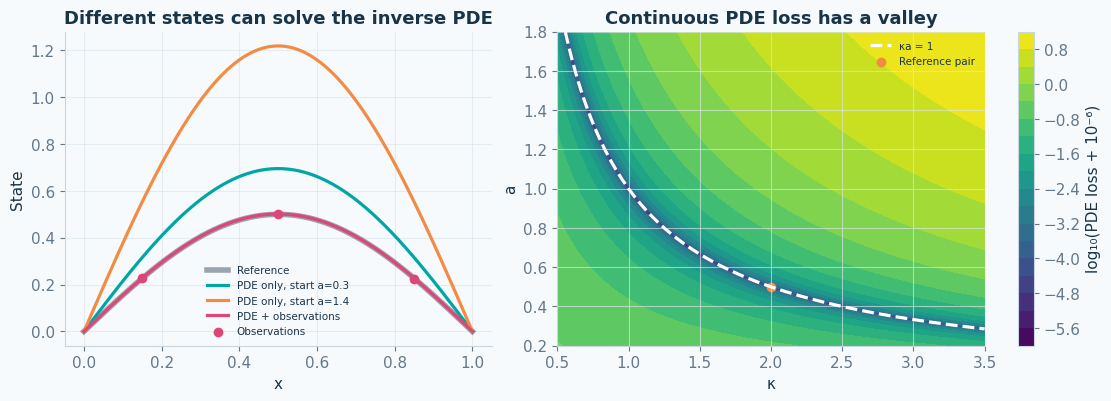

Sum of squared sensor sensitivities to amplitude: 1.4122


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), layout="constrained")
xx = check_x.numpy().ravel()
axes[0].plot(xx, np.sin(np.pi*xx)/TRUE_KAPPA, color=palette["navy"], alpha=.4, lw=4, label="Reference")
for name, model in fitted.items():
    with torch.no_grad():
        axes[0].plot(xx, model(check_x).numpy().ravel(), label=name)
axes[0].scatter(SENSOR_X, sensor_y.numpy(), color=palette["pink"], zorder=5, label="Observations")
axes[0].set(title="Different states can solve the inverse PDE", xlabel="x", ylabel="State")
kappa_grid = np.linspace(0.5, 3.5, 140)
amplitude_grid = np.linspace(0.2, 1.8, 120)
kk, aa = np.meshgrid(kappa_grid, amplitude_grid)
pde_landscape = 0.5*(kk*aa-1)**2
contours = axes[1].contourf(kk, aa, np.log10(pde_landscape+1e-6), levels=20, cmap="viridis")
axes[1].plot(kappa_grid, 1/kappa_grid, color="white", ls="--", label="κa = 1")
axes[1].scatter([TRUE_KAPPA], [1/TRUE_KAPPA], color=palette["orange"], label="Reference pair")
axes[1].set(title="Continuous PDE loss has a valley", xlabel="κ", ylabel="a", ylim=(0.2, 1.8))
fig.colorbar(contours, ax=axes[1], label="log₁₀(PDE loss + 10⁻⁶)")
for ax in axes:
    ax.legend(fontsize=7.5); ax.grid()
plt.show()
# For equal independent observation noise, this sum measures amplitude sensitivity.
sensor_sensitivity = float(torch.sin(math.pi*sensor_x).square().sum())
print(f"Sum of squared sensor sensitivities to amplitude: {sensor_sensitivity:.4f}")

## 2 · Your experiment and reflection

1. Compare three sensors near the endpoints with three near the midpoint. Repeat
   each configuration with five seeds and report the spread of recovered diffusivities.
2. Vary `DATA_WEIGHT` and noise. Report state-observation RMSE, $|\kappa a-1|$,
   and coefficient error separately. Why is the PDE residual alone insufficient?
3. Change the two PDE-only initial amplitudes. Check whether both runs approach
   the same product but different individual parameters.

**Hint:** $\partial u(x)/\partial a=\sin(\pi x)$. At the endpoints, the exact
Dirichlet values carry no amplitude information. For equal independent noise,
$\sum_i\sin^2(\pi x_i)$ measures the information in this one-parameter state model.

**Extension:** replace the sine-feature state with the MLP and hard boundary
factor from the setup. Use automatic differentiation to form $-\kappa u_\theta''-f$.
Keep coefficient uncertainty distinct from optimization error.

**Deliverable:** a sensor-location comparison across seeds and a short explanation
of how data remove the ambiguity in the product $\kappa a$.